# ShapeFit examples

In this notebook we will show how to perform ShapeFit fits to data power spectrum, using an emulator to speed up likelihood evaluation.
Look first at notebooks basic_examples.ipynb to get a flavor of *desilike* mechanisms.

## Fake power spectrum data

In [17]:
import numpy as np
from matplotlib import pyplot as plt

from cosmoprimo.fiducial import DESI

cosmo = DESI()
edges = np.linspace(0., 0.3, 31)
edges = np.column_stack([edges[:-1], edges[1:]])
k = np.mean(edges, axis=-1)
nmodes = 4. * np.pi / 3. * (edges[..., 1]**3 - edges[..., 0]**3)
z = 1.
pk = cosmo.get_fourier().pk_interpolator(of='delta_cb')(k, z=z)
b = 2.
f = cosmo.growth_rate(z)
shotnoise = np.ones_like(k) / 5e-4
volume = 1e10

ells = (0, 2, 4)
poles = []
poles.append((b**2 + 2. / 3. * f * b + 1. / 5. * f**2) * pk + shotnoise)
poles.append((4. / 3. * f * b + 4. / 7. * f**2) * pk)
poles.append(8. / 35 * f**2 * pk)
poles = np.array(poles, dtype='f8')

from lsstypes import Mesh2SpectrumPole, Mesh2SpectrumPoles
mean = [Mesh2SpectrumPole(k=k, k_edges=edges, num_raw=value, num_shotnoise=(ell == 0) * shotnoise, ell=ell) for ell, value in zip(ells, poles)]
mean = Mesh2SpectrumPoles(mean)

cov = [2. * (2. * np.pi)**3 / (2 * ell + 1) / (volume * nmodes) * poles[0]**2 for ell in ells]
cov = np.diag(np.concatenate(cov, axis=0))

rng = np.random.RandomState(seed=42)
mocks = []
for i in range(1001):
    tmp = mean.clone(value=rng.multivariate_normal(mean.value().ravel(), cov))
    mocks.append(tmp)
data, mocks = mocks[0], mocks[1:]

## ShapeFit likelihood

In [18]:
from desilike.theories.galaxy_clustering import ShapeFitSpectrum2Template, KaiserTracerSpectrum2Poles
from desilike.observables.galaxy_clustering import Spectrum2PolesObservable
from desilike.likelihoods import ObservablesGaussianLikelihood
from desilike import setup_logging, build, get_params
import lsstypes


template = ShapeFitSpectrum2Template(z=z, fiducial='DESI')
theory = KaiserTracerSpectrum2Poles(template=template)

data_sel = data.get(ells=[0, 2]).select(k=(0.02, 0.2))  # fit monopole and quadrupole, between 0.02 and 0.2 h/Mpc
covariance = lsstypes.cov(mocks).at.observable.match(data_sel)
observable = Spectrum2PolesObservable(data=data_sel, covariance=covariance, theory=theory)

# NOTE: parameter customization must happen AFTER building the observable above, not before:
# Spectrum2PolesObservable.__init__ calls theory.update(k=..., ells=...) internally to align the
# theory's grid with the data, which (being a full re-__init__) would otherwise silently
# discard any customization made on theory's params beforehand.
params = get_params(observable)
params['b1'].update(value=b)  # start from the truth
# Narrow reference distributions (used to draw starting points for profilers / samplers)
params['dm'].update(ref={'limits': [-0.001, 0.001]})
params['df'].update(ref={'limits': [0.99, 1.01]})
for name in ['qpar', 'qper']: params[name].update(ref={'limits': [0.998, 1.002]})

likelihood = ObservablesGaussianLikelihood(observables=[observable])

# NOTE: if we wanted to fit xi instead:
# theory = KaiserTracerCorrelation2Poles(template=template)
# observable = Correlation2PolesObservable(data=data_sel, covariance=covariance,
#                                          theory=theory)  # with data_sel = data.get(ells=[0, 2]).select(s=(40., 160.))
# The rest would be the same

setup_logging()
pipe = build(likelihood)
print('logL at default parameters =', pipe())

logL at default parameters = -17.968458230565233


In [19]:
from desilike.emulators import Emulator, Space

# Emulate the theory as set up by the observable (k and ells aligned with the data).
# A `Space` is where the emulator must be accurate: the region the chain will explore, not the
# whole prior -- over-covering is the most expensive mistake available here. `Space(theory)`
# would read the box off each parameter's `ref`, but the refs narrowed above are starting
# points for the sampler, far tighter than the region it explores, so state the box explicitly.
space = Space(bounds={'qpar': (0.95, 1.05), 'qper': (0.95, 1.05), 'df': (0.9, 1.1),
                      'dm': (-0.1, 0.1), 'b1': (1.6, 2.4), 'sn0': (-0.5, 0.5)},
              # per-axis resolution, a different knob from `budget` (the total degree of the
              # interpolant, which buys the interaction terms): the theory is linear in sn0,
              # so a single level is exact along that axis
              levels={'sn0': 1})
emulator = Emulator(theory, space, budget=2)
print(len(emulator.nodes()), 'nodes')  # size the training before paying for it
emulator.train()

# `to_calculator()` returns an instance of the theory's own class whose state is predicted
# rather than computed -- a drop-in wherever the original went. It deploys onto a copy of the
# calculator it was built from, so the pipeline this emulator came from stays usable: both
# graphs live, and they share their Parameters by name.
emulated = emulator.to_calculator()

# An emulated calculator returns `self` (it is built to be a dependency, read through its
# attributes), so evaluate it and read `.poles`.
point = dict(qpar=1.002, qper=0.998, dm=0.005, df=1.005, b1=2.1, sn0=0.1)
poles_true = np.asarray(build(theory)(**point))
build(emulated)(**point)
print('Max relative emulation error:', np.max(np.abs(np.asarray(emulated.poles) / poles_true - 1.)))

import os
base_dir = '_tests'
os.makedirs(base_dir, exist_ok=True)
kaiser_emulator_fn = os.path.join(base_dir, 'kaiser_emulator.h5')
emulator.write(kaiser_emulator_fn)

83 nodes
[000004.54]  10-10 12:49  Emulator                     INFO     training on 83 nodes over 6 parameters; 0 handled exactly
[000004.54]  10-10 12:49  Emulator                     INFO     node box: qpar [0.95, 1.05], qper [0.95, 1.05], df [0.9, 1.1], dm [-0.1, 0.1], b1 [1.6, 2.4], sn0 [-0.5, 0.5]
[000004.54]  10-10 12:49  TrainingSet                  INFO     83/83 nodes to evaluate; no checkpoint (nothing is resumable)
[000004.79]  10-10 12:49  TrainingSet                  INFO     50/83 nodes
[000004.79]  10-10 12:49  TrainingSet                  INFO     training complete (83/83 nodes)
Max relative emulation error: 9.538143520115838e-05


'_tests/kaiser_emulator.h5'

## Sampling
Let us draw MC samples of the likelihood (actually posterior, including parameter priors).

In [20]:
from desilike import Sampler, Posterior
from desilike.samplers import Zeus

# Read the emulator back. The emulator saved to file has no Calculator of its own (a Calculator
# is not state, and its constructor arguments are the caller's), so it is handed the ones it
# needs. Swapping it into the observable -- update() re-runs the observable's __init__ in-place
# with the new theory -- is left commented out here, to sample the exact theory below; the
# section with dA further down does make the swap.
emulated = Emulator.read(kaiser_emulator_fn).to_calculator()
#observable.update(theory=emulated)

# Sample the posterior = likelihood + priors: wrap the likelihood in Posterior.
# (Sampling the bare likelihood would let walkers wander far outside the priors.)
pipe = build(Posterior(likelihood))
! rm -vr _tests/chain_fs_shapefit
sampler = Sampler(pipe, kernel=Zeus(), rng=42, output_dir='_tests/chain_fs_shapefit')
# We run samples until convergence, considered reached when Gelman-Rubin stabilizes below 1.05
samples = sampler.run(min_steps=500, gelman_rubin=1.05)

/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
removed directory '_tests/chain_fs_shapefit'
[000009.77]  10-10 12:49  EnsembleSampler              INFO     Varied parameters: ['qpar', 'qper', 'df', 'dm', 'b1', 'sn0']
[000009.77]  10-10 12:49  EnsembleSampler              INFO     Samples will be written to: _tests/chain_fs_shapefit
[000010.19]  10-10 12:49  root                         INFO     Initialising ensemble of 24 walkers...
[000019.48]  10-10 12:49  EnsembleSampler              INFO     Diagnostics:
[000019.51]  10-10 12:49  EnsembleSampler              INFO     Gelman-Rubin: 1.03
[000019.51]  10-10 12:49  EnsembleSampler              INFO     1.03 < 1.05 (passed)
[000019.51]  10-10 12:49  EnsembleSampler              INFO     Geweke: 0.33
[000019.51]  10-10 12:49  EnsembleSampler       

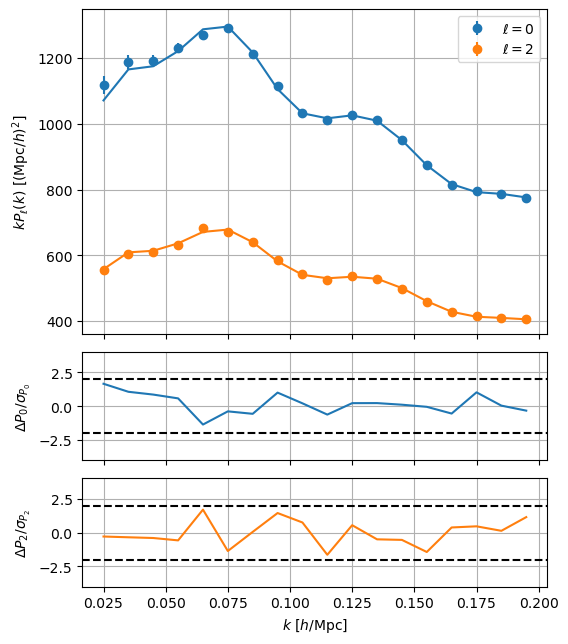

In [21]:
# Evaluate the likelihood at the maximum-posterior sample and plot the fit
names = get_params(likelihood).select(varied=True, derived=False).names()
idx = np.unravel_index(np.argmax(samples.logposterior), samples.logposterior.shape)
best = {name: np.asarray(samples[name].value)[idx] for name in names}
pipe(**best)
observable.plot()
plt.show()

In [22]:
chain = samples.remove_burnin(0.5)[::10]
print(chain.to_stats(tablefmt='pretty'))

+------+--------+---------+---------+--------+-----------------+-----------------+
|      | argmax |  mean   | median  |  std   | quantile:1sigma | interval:1sigma |
+------+--------+---------+---------+--------+-----------------+-----------------+
| qpar | 1.0002 | 1.0001  | 1.0002  | 0.0025 | +0.0026/-0.0025 | +0.0025/-0.0025 |
| qper | 0.9933 | 0.9941  | 0.9943  | 0.0046 | +0.0048/-0.0046 | +0.0052/-0.0041 |
|  df  | 0.9886 | 0.9911  | 0.9912  | 0.0097 | +0.0095/-0.0094 | +0.0092/-0.0096 |
|  dm  | 0.0000 | -0.0015 | -0.0015 | 0.0061 | +0.0059/-0.0061 | +0.0069/-0.0049 |
|  b1  | 1.9870 | 1.9899  | 1.9898  | 0.0083 | +0.0082/-0.0080 | +0.0082/-0.0080 |
| sn0  | 0.0026 | 0.0024  | 0.0024  | 0.0030 | +0.0031/-0.0031 | +0.0027/-0.0033 |
+------+--------+---------+---------+--------+-----------------+-----------------+


Removed no burn in
[000023.53]  10-10 12:49  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral
[000023.54]  10-10 12:49  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral


[000025.36]  10-10 12:49  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral
[000025.36]  10-10 12:49  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral


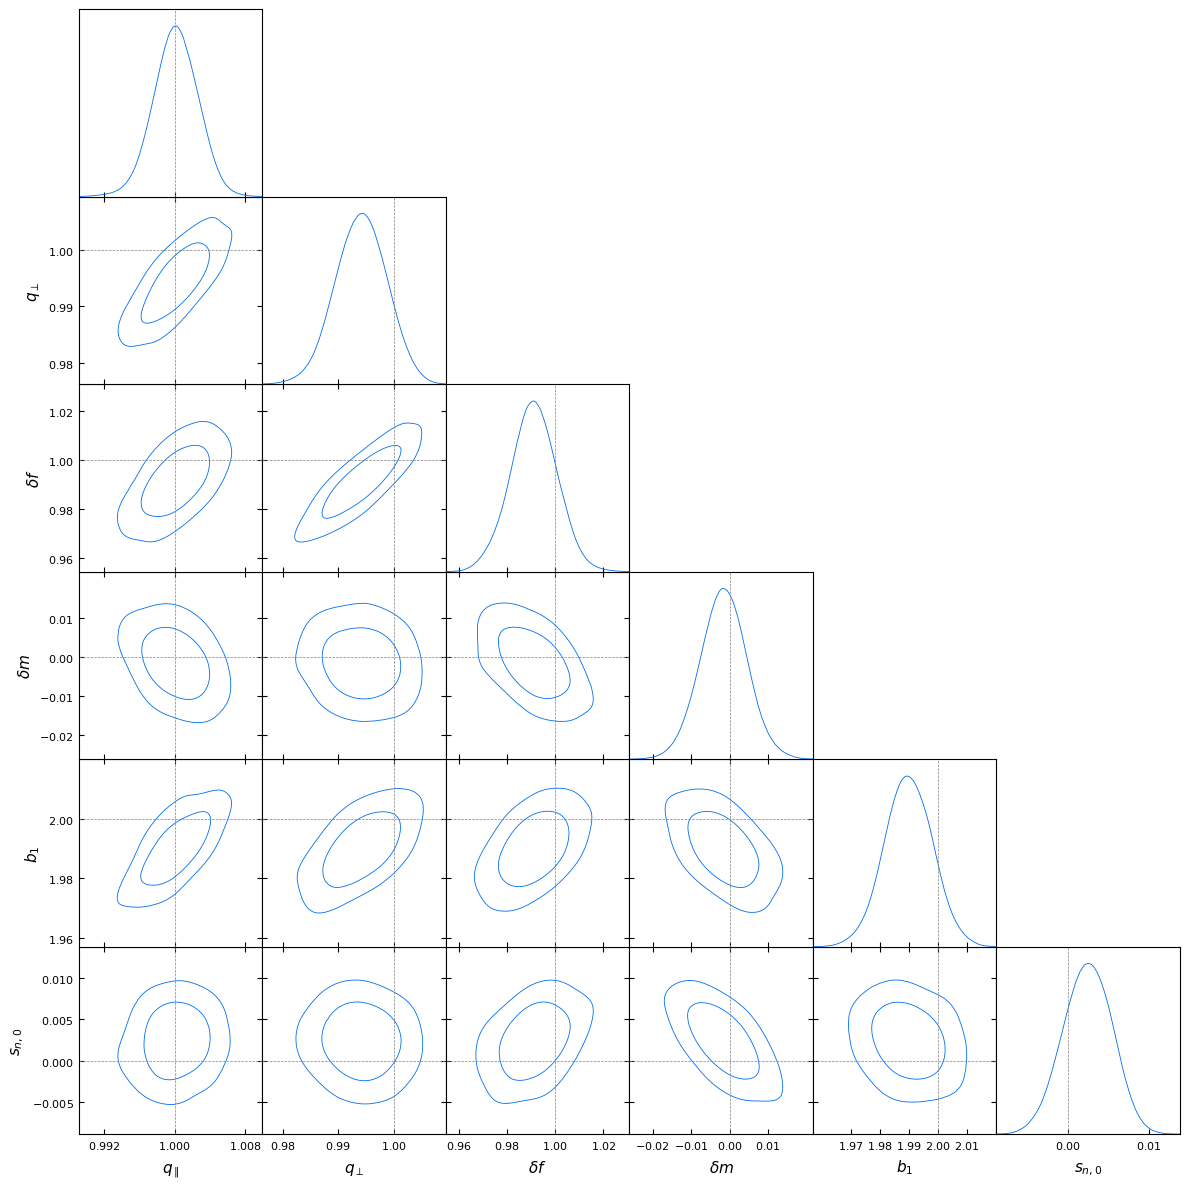

In [23]:
from desilike.samples import plotting
plotting.plot_triangle(chain, markers={'qpar': 1., 'qper': 1., 'df': 1., 'dm': 0., 'b1': b, 'sn0': 0.})

# Free n in shapefit

In [24]:
from desilike.theories.galaxy_clustering import ShapeFitSpectrum2Template, KaiserTracerSpectrum2Poles
from desilike.observables.galaxy_clustering import Spectrum2PolesObservable
from desilike.likelihoods import ObservablesGaussianLikelihood
from desilike import setup_logging, build, get_params
import lsstypes


template = ShapeFitSpectrum2Template(z=z, fiducial='DESI')
theory = KaiserTracerSpectrum2Poles(template=template)

data_sel = data.get(ells=[0, 2]).select(k=(0.02, 0.2))  # fit monopole and quadrupole, between 0.02 and 0.2 h/Mpc
covariance = lsstypes.cov(mocks).at.observable.match(data_sel)
observable = Spectrum2PolesObservable(data=data_sel, covariance=covariance, theory=theory)

# NOTE: parameter customization must happen AFTER building the observable above, not before:
# Spectrum2PolesObservable.__init__ calls theory.update(k=..., ells=...) internally to align the
# theory's grid with the data, which (being a full re-__init__) would otherwise silently
# discard any customization made on theory's params beforehand.
params = get_params(observable)
params['b1'].update(value=b)  # start from the truth
# Narrow reference distributions (used to draw starting points for profilers / samplers)
params['dm'].update(ref={'limits': [-0.001, 0.001]})
params['df'].update(ref={'limits': [0.99, 1.01]})
params['dn'].update(ref={'limits': [-0.001, 0.001]}, fixed = False)
for name in ['qpar', 'qper']: params[name].update(ref={'limits': [0.998, 1.002]})

likelihood = ObservablesGaussianLikelihood(observables=[observable])

# NOTE: if we wanted to fit xi instead:
# theory = KaiserTracerCorrelation2Poles(template=template)
# observable = Correlation2PolesObservable(data=data_sel, covariance=covariance,
#                                          theory=theory)  # with data_sel = data.get(ells=[0, 2]).select(s=(40., 160.))
# The rest would be the same

setup_logging()
pipe = build(likelihood)
print('logL at default parameters =', pipe())

logL at default parameters = -17.968458230565233


/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/cosmoprimo/main/lib/python3.12/site-packages/cosmoprimo/eisenstein_hu.py:25: UserWarning: EisensteinHuNoWiggleEngine cannot cope with massive neutrinos
  warnings.warn(


In [25]:
from desilike import Sampler, Posterior
from desilike.samplers import Zeus

# Read the emulator back. The emulator saved to file has no Calculator of its own (a Calculator
# is not state, and its constructor arguments are the caller's), so it is handed the ones it
# needs. Swapping it into the observable -- update() re-runs the observable's __init__ in-place
# with the new theory -- is left commented out here, to sample the exact theory below; the
# section with dA further down does make the swap.
emulated = Emulator.read(kaiser_emulator_fn).to_calculator()
#observable.update(theory=emulated)

# Sample the posterior = likelihood + priors: wrap the likelihood in Posterior.
# (Sampling the bare likelihood would let walkers wander far outside the priors.)
pipe = build(Posterior(likelihood))
! rm -vr _tests/chain_fs_shapefit_dn
sampler = Sampler(pipe, kernel=Zeus(), rng=42, output_dir='_tests/chain_fs_shapefit_dn')
# We run samples until convergence, considered reached when Gelman-Rubin stabilizes below 1.05
samples = sampler.run(min_steps=500, gelman_rubin=1.05)

/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/conda/lib/python3.12/pty.py:95: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
removed '_tests/chain_fs_shapefit_dn/samples_1.h5'
removed '_tests/chain_fs_shapefit_dn/checks.json'
removed '_tests/chain_fs_shapefit_dn/rng_1.json'
removed directory '_tests/chain_fs_shapefit_dn'
[000005.24]  10-10 12:49  EnsembleSampler              INFO     Varied parameters: ['qpar', 'qper', 'df', 'dm', 'dn', 'b1', 'sn0']
[000005.24]  10-10 12:49  EnsembleSampler              INFO     Samples will be written to: _tests/chain_fs_shapefit_dn


/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/desilike/refactor-jax/lib/python3.12/site-packages/desilike/samplers/zeus.py:67: UserWarning: Zeus does not support random seeds. Results are not deterministic.
  warnings.warn('Zeus does not support random seeds. Results are not deterministic.')


[000005.74]  10-10 12:49  root                         INFO     Initialising ensemble of 28 walkers...
[000019.14]  10-10 12:49  EnsembleSampler              INFO     Diagnostics:
[000019.17]  10-10 12:49  EnsembleSampler              INFO     Gelman-Rubin: 1.02
[000019.17]  10-10 12:49  EnsembleSampler              INFO     1.02 < 1.05 (passed)
[000019.17]  10-10 12:49  EnsembleSampler              INFO     Geweke: 0.239
[000019.17]  10-10 12:49  EnsembleSampler              INFO     Effective Sample Size: 699
[000019.18]  10-10 12:49  root                         INFO     Initialising ensemble of 28 walkers...
[000021.31]  10-10 12:49  EnsembleSampler              INFO     Diagnostics:
[000021.35]  10-10 12:49  EnsembleSampler              INFO     Gelman-Rubin: 1
[000021.35]  10-10 12:49  EnsembleSampler              INFO     1 < 1.05 (passed)
[000021.35]  10-10 12:49  EnsembleSampler              INFO     Geweke: 0.0827
[000021.35]  10-10 12:49  EnsembleSampler              INFO   

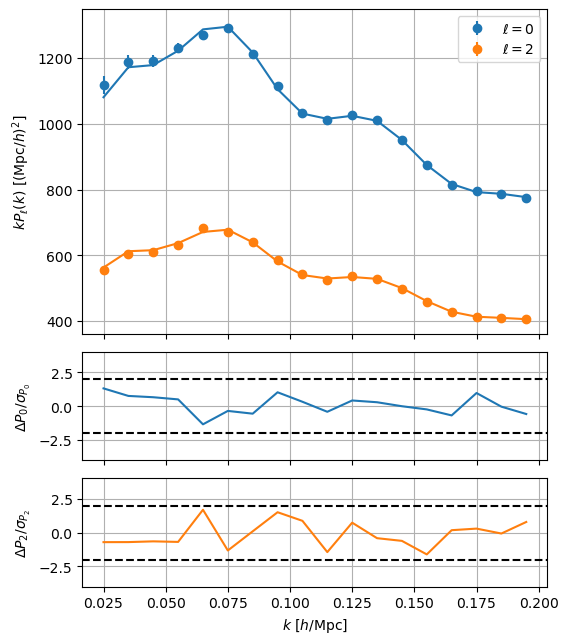

In [26]:
# Evaluate the likelihood at the maximum-posterior sample and plot the fit
names = get_params(likelihood).select(varied=True, derived=False).names()
idx = np.unravel_index(np.argmax(samples.logposterior), samples.logposterior.shape)
best = {name: np.asarray(samples[name].value)[idx] for name in names}
pipe(**best)
observable.plot()
plt.show()

In [27]:
chain = samples.remove_burnin(0.5)[::10]
print(chain.to_stats(tablefmt='pretty'))

+------+--------+--------+--------+--------+-----------------+-----------------+
|      | argmax |  mean  | median |  std   | quantile:1sigma | interval:1sigma |
+------+--------+--------+--------+--------+-----------------+-----------------+
| qpar | 1.0014 | 1.0007 | 1.0007 | 0.0027 | +0.0028/-0.0027 | +0.0031/-0.0024 |
| qper | 0.9954 | 0.9949 | 0.9950 | 0.0050 | +0.0052/-0.0052 | +0.0057/-0.0045 |
|  df  | 0.996  | 0.993  | 0.993  | 0.011  |  +0.011/-0.010  | +0.0114/-0.0100 |
|  dm  | -0.029 | -0.031 | -0.030 | 0.029  |  +0.029/-0.029  |  +0.023/-0.033  |
|  dn  | 0.017  | 0.019  | 0.019  | 0.018  |  +0.018/-0.017  |  +0.017/-0.018  |
|  b1  | 1.998  | 1.999  | 1.999  | 0.012  |  +0.013/-0.013  |  +0.012/-0.013  |
| sn0  | 0.0024 | 0.0008 | 0.0007 | 0.0031 | +0.0032/-0.0032 | +0.0035/-0.0027 |
+------+--------+--------+--------+--------+-----------------+-----------------+


Removed no burn in
[000023.37]  10-10 12:49  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral
[000023.38]  10-10 12:49  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral


[000025.84]  10-10 12:49  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral
[000025.85]  10-10 12:49  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral


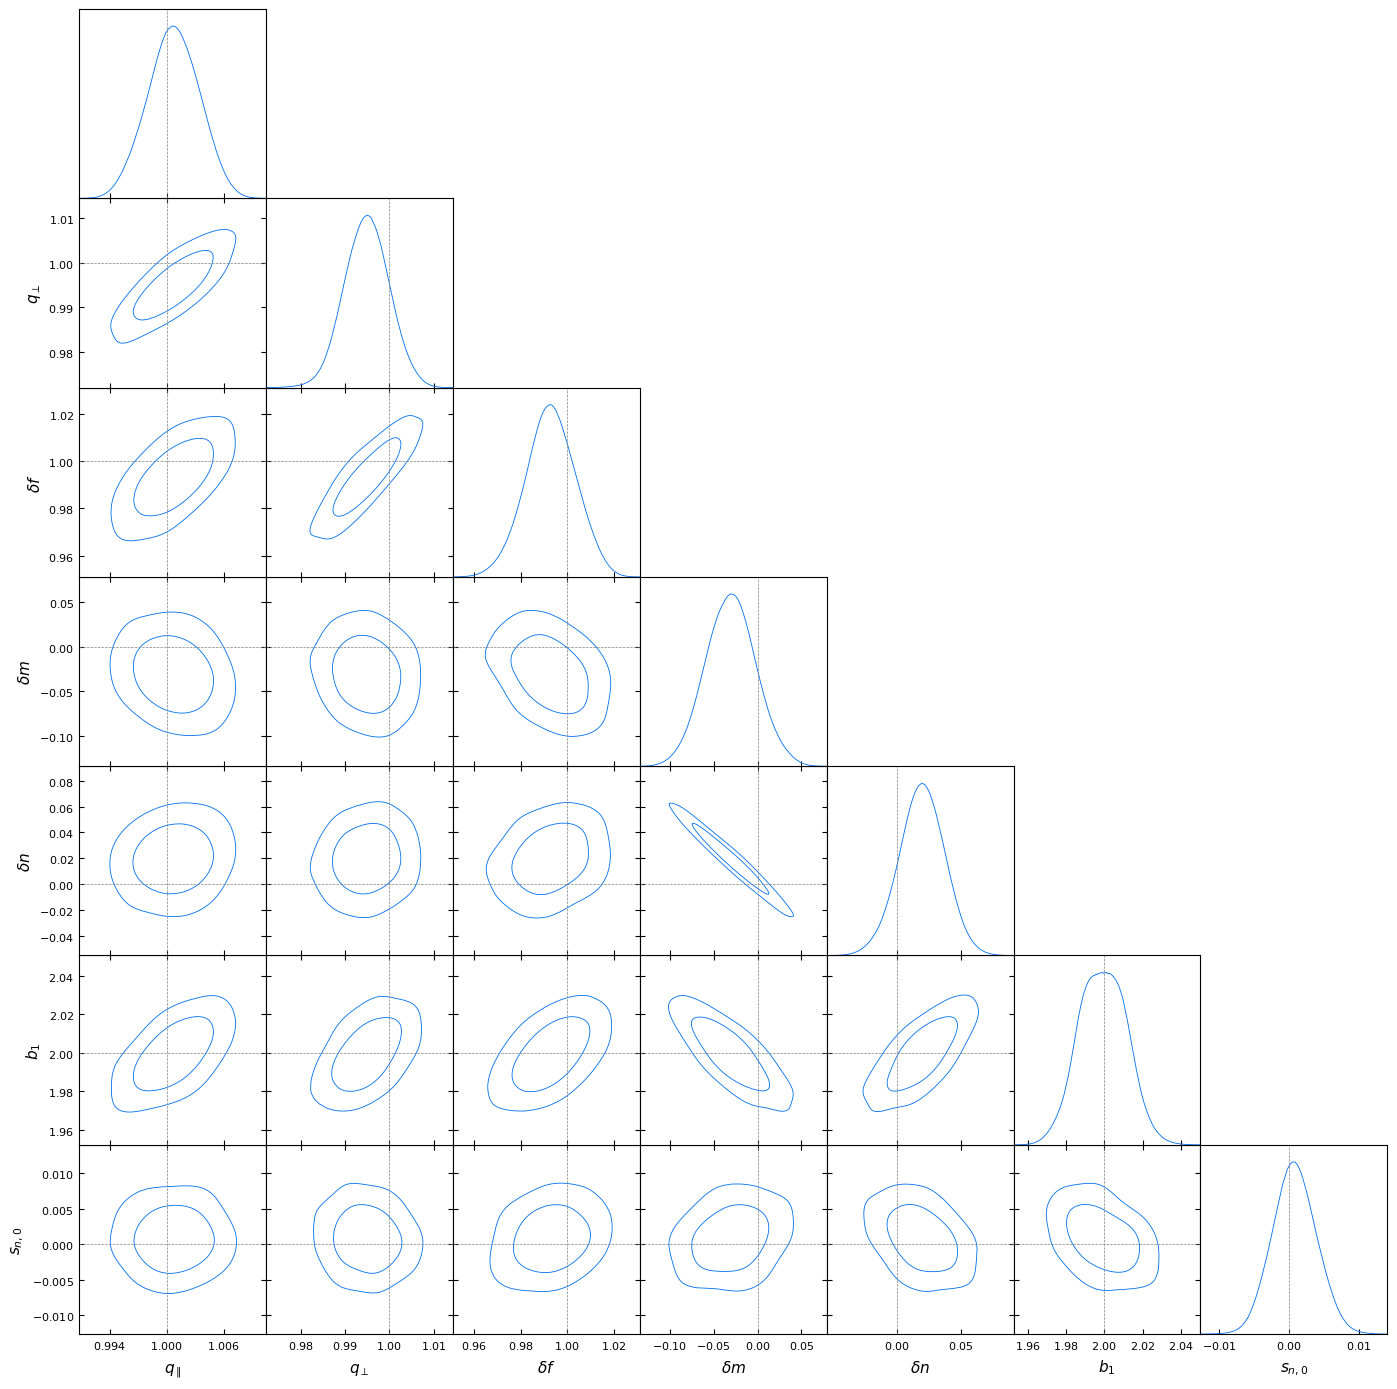

In [28]:
from desilike.samples import plotting
plotting.plot_triangle(chain, markers={'qpar': 1., 'qper': 1., 'df': 1., 'dm': 0., 'b1': b, 'sn0': 0., 'dn':0.})

# Modified shapefit with separate amplitude parameter $dA$

## Fit power spectrum again with free $dA$

In [10]:
template = ShapeFitSpectrum2Template(z=z, fiducial='DESI')
theory = KaiserTracerSpectrum2Poles(template=template)

data_sel = data.get(ells=[0, 2]).select(k=(0.02, 0.2))  # fit monopole and quadrupole, between 0.02 and 0.2 h/Mpc
covariance = lsstypes.cov(mocks).at.observable.match(data_sel)
observable = Spectrum2PolesObservable(data=data_sel, covariance=covariance, theory=theory)

# NOTE: parameter customization must happen AFTER building the observable above, not before:
# Spectrum2PolesObservable.__init__ calls theory.update(k=..., ells=...) internally to align the
# theory's grid with the data, which (being a full re-__init__) would otherwise silently
# discard any customization made on theory's params beforehand.
params = get_params(observable)
params['b1'].update(value=b)  # start from the truth
# Narrow reference distributions (used to draw starting points for profilers / samplers)
params['dm'].update(ref={'limits': [-0.001, 0.001]})
params['df'].update(ref={'limits': [0.99, 1.01]})
params['dA'].update(ref={'limits': [0.99, 1.01]}, fixed = False)
for name in ['qpar', 'qper']: params[name].update(ref={'limits': [0.998, 1.002]})

likelihood = ObservablesGaussianLikelihood(observables=[observable])

# NOTE: if we wanted to fit xi instead:
# theory = KaiserTracerCorrelation2Poles(template=template)
# observable = Correlation2PolesObservable(data=data_sel, covariance=covariance,
#                                          theory=theory)  # with data_sel = data.get(ells=[0, 2]).select(s=(40., 160.))
# The rest would be the same

setup_logging()
pipe = build(likelihood)
print('logL at default parameters =', pipe())

logL at default parameters = -17.96845823056523


In [11]:
from desilike.emulators import Emulator, Space

# Emulate the theory as set up by the observable (k and ells aligned with the data).
# A `Space` is where the emulator must be accurate: the region the chain will explore, not the
# whole prior -- over-covering is the most expensive mistake available here. `Space(theory)`
# would read the box off each parameter's `ref`, but the refs narrowed above are starting
# points for the sampler, far tighter than the region it explores, so state the box explicitly.
space = Space(bounds={'qpar': (0.95, 1.05), 'qper': (0.95, 1.05), 'df': (0.9, 1.1), 'dA': (0.9, 1.1),
                      'dm': (-0.1, 0.1), 'b1': (1.6, 2.4), 'sn0': (-0.5, 0.5)},
              # per-axis resolution, a different knob from `budget` (the total degree of the
              # interpolant, which buys the interaction terms): the theory is linear in sn0,
              # so a single level is exact along that axis
              levels={'sn0': 1})
emulator = Emulator(theory, space, budget=2)
print(len(emulator.nodes()), 'nodes')  # size the training before paying for it
emulator.train()

# `to_calculator()` returns an instance of the theory's own class whose state is predicted
# rather than computed -- a drop-in wherever the original went. Give it a FRESH template:
# by default it reuses the original's constructor arguments, and building a second pipeline
# on the same template (and its cosmology) leaves the first one unusable.
emulated = emulator.to_calculator()

# An emulated calculator returns `self` (it is built to be a dependency, read through its
# attributes), so evaluate it and read `.poles`.
point = dict(qpar=1.002, qper=0.998, dm=0.005, df=1.005, dA=1.005, b1=2.1, sn0=0.1)
poles_true = np.asarray(build(theory)(**point))
build(emulated)(**point)
print('Max relative emulation error:', np.max(np.abs(np.asarray(emulated.poles) / poles_true - 1.)))

import os
base_dir = '_tests'
os.makedirs(base_dir, exist_ok=True)
kaiser_emulator_fn = os.path.join(base_dir, 'Ap_kaiser_emulator.h5')
emulator.write(kaiser_emulator_fn)

111 nodes
[000015.02]  09-16 23:55  Emulator                     INFO     training on 111 nodes over 7 parameters; 0 handled exactly
[000015.02]  09-16 23:55  Emulator                     INFO     node box: qpar [0.95, 1.05], qper [0.95, 1.05], df [0.9, 1.1], dA [0.9, 1.1], dm [-0.1, 0.1], b1 [1.6, 2.4], sn0 [-0.5, 0.5]
[000015.02]  09-16 23:55  TrainingSet                  INFO     111/111 nodes to evaluate; no checkpoint (nothing is resumable)
[000015.24]  09-16 23:55  TrainingSet                  INFO     50/111 nodes
[000015.25]  09-16 23:55  TrainingSet                  INFO     100/111 nodes
[000015.25]  09-16 23:55  TrainingSet                  INFO     training complete (111/111 nodes)
Max relative emulation error: 9.226499971792812e-05


'_tests/Ap_kaiser_emulator.h5'

In [12]:
from desilike import Sampler, Posterior
from desilike.samplers import Zeus, PocoMC, Nautilus, Emcee

# Swap the theory for its emulator: update() re-runs the observable's __init__ in-place with
# the new theory (the likelihood holds the same observable instance, so it picks up the swap
# when we rebuild below).
#
# Reconfiguring is allowed and costs the graphs built over this observable: `pipe` above is
# invalidated here, and would say so if called. This cell rebuilds it below.
emulated = Emulator.read(kaiser_emulator_fn).to_calculator()
observable.update(theory=emulated)
# update() re-ran __init__, which rebuilt the parameters: re-apply the customization above
params = get_params(observable)
params['b1'].update(value=b)
params['dm'].update(ref={'limits': [-0.001, 0.001]})
params['df'].update(ref={'limits': [0.99, 1.01]})
params['dA'].update(ref={'limits': [0.99, 1.01]}, fixed=False)
for name in ['qpar', 'qper']: params[name].update(ref={'limits': [0.998, 1.002]})

# Sample the posterior = likelihood + priors: wrap the likelihood in Posterior.
# (Outside its trained box the emulator predicts NaN, i.e. -inf posterior, so the sampler
# rejects those points instead of extrapolating.)
pipe = build(Posterior(likelihood))
! rm -rfv _tests/chain_fs_shapefit_Ap/
sampler = Sampler(pipe, kernel=Emcee(), rng=42, output_dir='_tests/chain_fs_shapefit_Ap')
# We run samples until convergence, considered reached when Gelman-Rubin stabilizes below 1.05
samples = sampler.run(min_steps=2000, gelman_rubin=1.02)
#samples = sampler.run()

/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/conda/lib/python3.12/pty.py:95: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
removed '_tests/chain_fs_shapefit_Ap/samples_1.h5'
removed '_tests/chain_fs_shapefit_Ap/checks.json'
removed '_tests/chain_fs_shapefit_Ap/rng_1.json'
removed directory '_tests/chain_fs_shapefit_Ap/'
[000037.46]  09-16 23:55  EnsembleSampler              INFO     Varied parameters: ['qpar', 'qper', 'df', 'dA', 'dm', 'b1', 'sn0']
[000037.46]  09-16 23:55  EnsembleSampler              INFO     Samples will be written to: _tests/chain_fs_shapefit_Ap
[000038.94]  09-16 23:55  Emcee                        INFO     total likelihood evaluations: 8372
[000039.04]  09-16 23:55  EnsembleSampler              INFO     Diagnostics:
[000039.07]  09-16 23:55  EnsembleSampler              INFO     Gelman-Rubin: 1.29
[000039.07]  09-16 23:55  EnsembleSampler          

In [13]:
chain = samples.remove_burnin(0.5)[::10]
print(chain.to_stats(tablefmt='pretty'))

+------+---------+---------+---------+--------+-----------------+-----------------+
|      | argmax  |  mean   | median  |  std   | quantile:1sigma | interval:1sigma |
+------+---------+---------+---------+--------+-----------------+-----------------+
| qpar | 1.0000  | 1.0003  | 1.0003  | 0.0025 | +0.0026/-0.0026 | +0.0029/-0.0022 |
| qper | 0.9940  | 0.9944  | 0.9945  | 0.0047 | +0.0047/-0.0046 | +0.0048/-0.0043 |
|  df  |  0.946  |  0.991  |  0.990  | 0.030  |  +0.035/-0.034  |  +0.026/-0.041  |
|  dA  |  1.094  |  1.001  |  1.000  | 0.059  |  +0.071/-0.070  |  +0.098/-0.037  |
|  dm  | -0.0002 | -0.0007 | -0.0006 | 0.0058 | +0.0056/-0.0057 | +0.0059/-0.0054 |
|  b1  |  1.902  |  1.992  |  1.990  | 0.059  |  +0.070/-0.069  |  +0.044/-0.087  |
| sn0  | 0.0015  | 0.0020  | 0.0019  | 0.0029 | +0.0029/-0.0029 | +0.0027/-0.0031 |
+------+---------+---------+---------+--------+-----------------+-----------------+


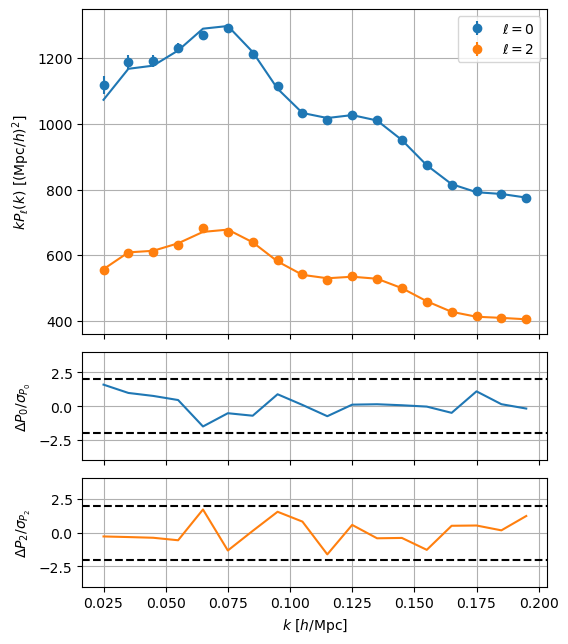

In [14]:
# Evaluate the likelihood at the maximum-posterior sample and plot the fit
names = get_params(likelihood).select(varied=True, derived=False).names()
idx = np.unravel_index(np.argmax(samples.logposterior), samples.logposterior.shape)
best = {name: np.asarray(samples[name].value)[idx] for name in names}
pipe(**best)
observable.plot()
plt.show()

Removed no burn in
Removed no burn in
[000125.31]  09-16 23:56  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral
[000125.32]  09-16 23:56  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral


[000127.79]  09-16 23:57  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral
[000127.79]  09-16 23:57  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral


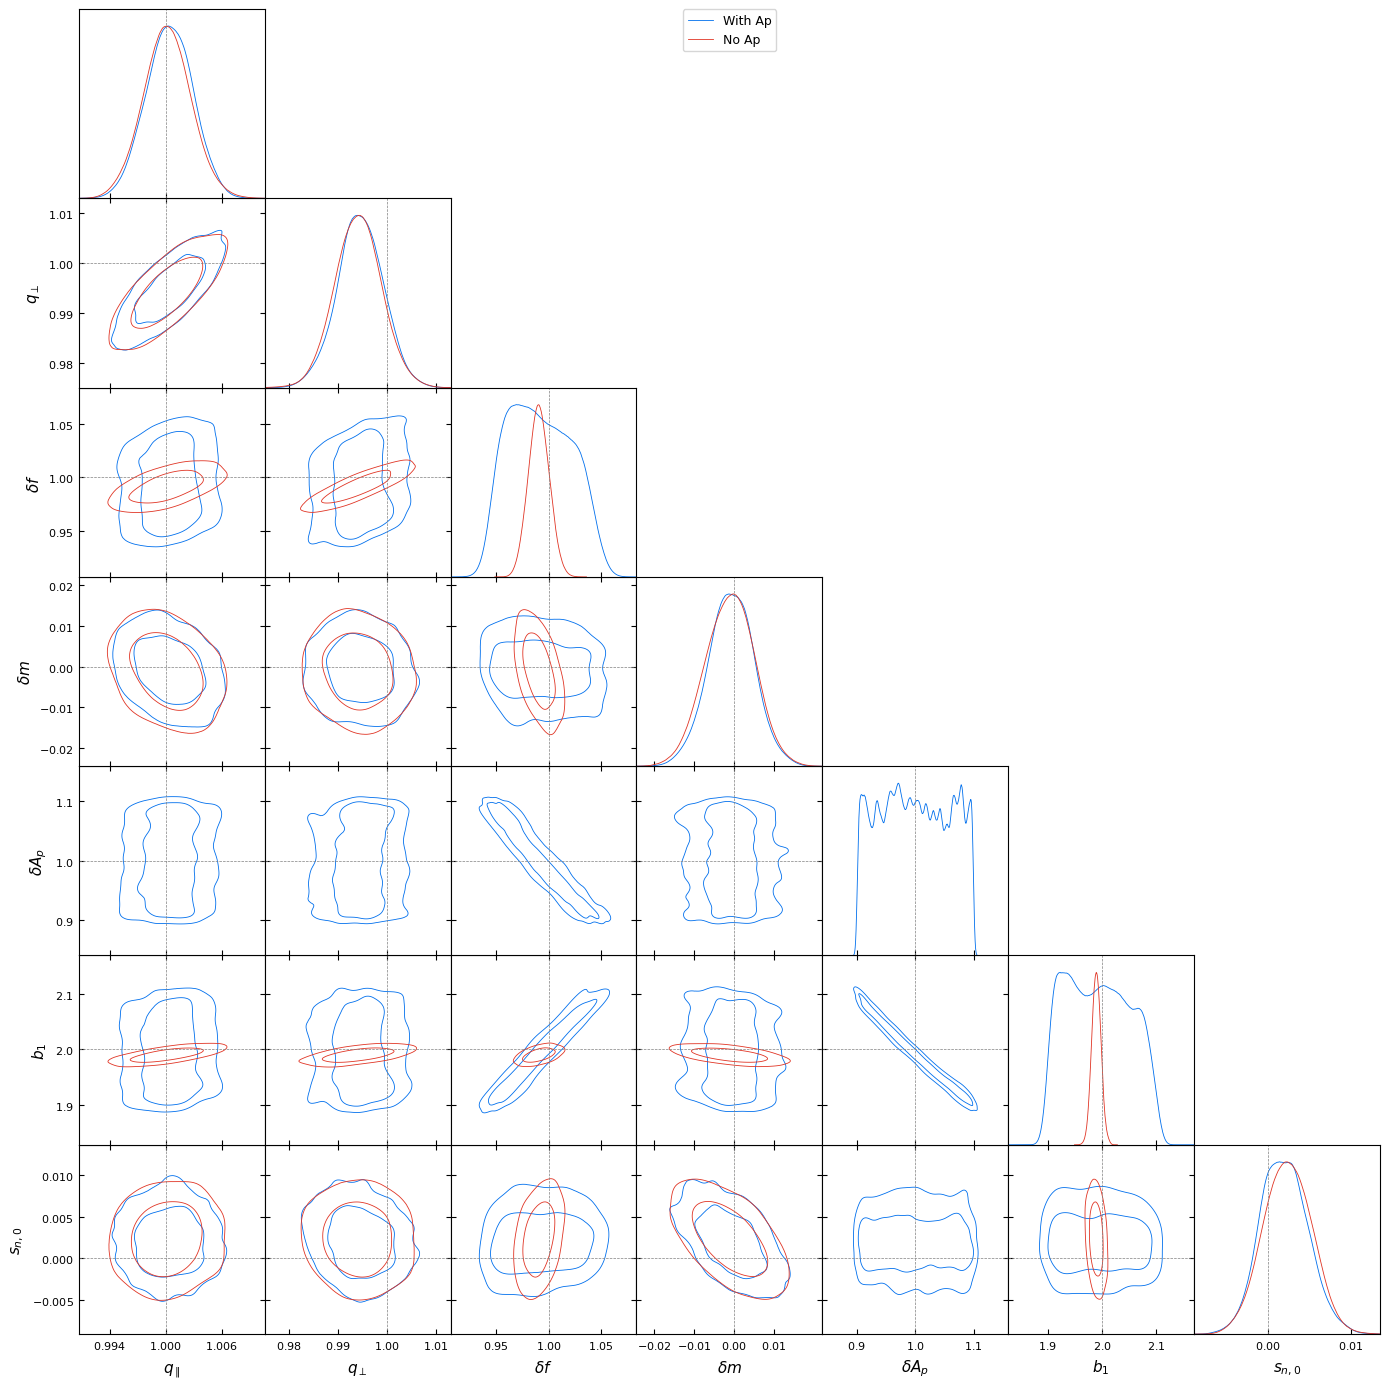

In [16]:
from desilike.samples import plotting
from desilike.samples import MCSamples
chain = MCSamples.read('_tests/chain_fs_shapefit_Ap/samples_1.h5').remove_burnin(0.3)[::5]
chain_no_Ap = MCSamples.read('_tests/chain_fs_shapefit/samples_1.h5').remove_burnin(0.3)[::5]

plotting.plot_triangle([chain, chain_no_Ap], 
                       markers={'qpar': 1., 'qper': 1., 'df': 1., 'dA':1., 'dm': 0., 'b1': b, 'sn0': 0.},
                       params = ['qpar', 'qper', 'df', 'dm', 'dA', 'logdA', 'b1', 'sn0'],
                      labels = ["With Ap", "No Ap"])

# Now do ShapeFit with the bispectrum

## Generating fake bispectrum data using FOLPS

⚠️ JAX is using CPU. Devices: [CpuDevice(id=0)]
Calculating matrices (no save path specified)


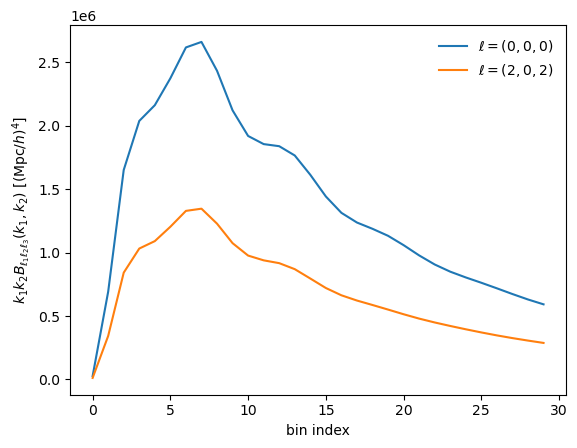

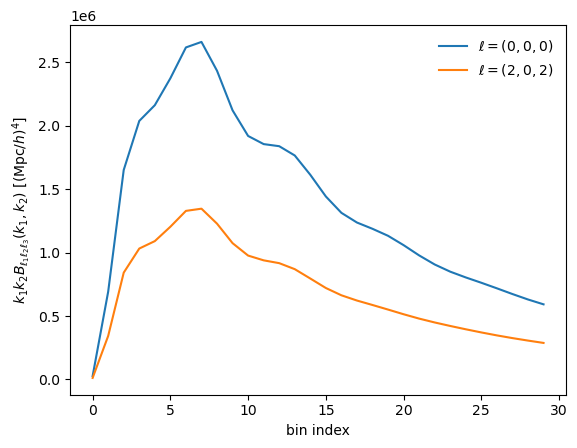

In [17]:
from desilike.theories.galaxy_clustering import FOLPSTracerSpectrum3Poles
from desilike.theories.galaxy_clustering.template import DirectSpectrum2Template
from lsstypes import Mesh3SpectrumPole, Mesh3SpectrumPoles
cosmo = DESI()
edges = np.linspace(0., 0.3, 31)
edges = np.column_stack([edges[:-1], edges[1:]])
k = np.mean(edges, axis=-1)     
theory_b = FOLPSTracerSpectrum3Poles(template=DirectSpectrum2Template(z = z, fiducial = cosmo),
                                            k = np.c_[k, k])

b1, b2, bs = b, 0.5, -0.2
theory_graph = build(theory_b)
theory_values = theory_graph(b1 = b1, b2 = b2, bs = bs, c1 = 0, c2 = 0, X_FoG = 0)
poles = []
for ill, ell in enumerate(theory_b.ells):
    
    pole = Mesh3SpectrumPole(
                k=np.c_[k, k],                # shape (n_k, 2)
                k_edges=np.c_[edges, edges].reshape(-1, 2, 2),  # (n_k, 2, 2)
                num_raw=theory_values[ill],
                ell=theory_b.ells[ill],
                basis='sugiyama'
            )
    poles.append(pole)
mean_bispec = Mesh3SpectrumPoles(poles)
mean_bispec.plot()


In [18]:

k1 = k
k2 = k
dk = np.diff(edges)
dk1_2d, dk2_2d = np.meshgrid(dk, dk, indexing='ij')
k1_2d, k2_2d = np.meshgrid(k1, k2, indexing='ij')
volume = 1e10
# Phase-space volume factor for triangles
nmodes_k = 8 * np.pi**2 * k1_2d**2 * k2_2d**2 * dk1_2d * dk2_2d
N_tri = nmodes_k * volume / (2 * np.pi)**6
N_tri = np.maximum(N_tri, 1).astype('i8')

def safe_pk(k, b1, z):
    pk = cosmo.get_fourier().pk_interpolator(of='delta_cb')(k.ravel(), z=z)
    return b1**2 * pk.reshape(k.shape)
p1_2d = safe_pk(k1_2d, b1, z)
p2_2d = safe_pk(k2_2d, b1, z)
k3_mean = np.sqrt(k1_2d**2 + k2_2d**2) # representative k3 for disconnected covariance
p3_2d = safe_pk(k3_mean, b1, z)

var = []
for ell in mean_bispec.ells:
    ell_factor = 1
    for ll in ell:
        ell_factor *= 2 * (ll + 1)
    # Disconnected bispectrum covariance scales roughly as P1 * P2 * P3 / N_tri
    v = ell_factor * p1_2d * p2_2d * p3_2d / N_tri
    v = v + np.max(v) * 1e-4 # Add a numerical floor to avoid exactly zero variance
    var.append(np.diag(v))

cov_b = np.diag(np.concatenate(var))



In [19]:
rng = np.random.RandomState(seed=42)
mocks_bispec = []
for i in range(1001):
    tmp = mean_bispec.clone(value=rng.multivariate_normal(mean_bispec.value().ravel(), cov_b))
    mocks_bispec.append(tmp)

data_bispec, mocks_bispec = mocks_bispec[0], mocks_bispec[1:]
print(f"Successfully generated data and {len(mocks)} mocks for bispectrum.")



Successfully generated data and 1000 mocks for bispectrum.


## Generating likelihood

In [20]:

from desilike.theories.galaxy_clustering import FOLPSTracerSpectrum3Poles
from desilike.observables.galaxy_clustering import Spectrum3PolesObservable
template_b = ShapeFitSpectrum2Template(z=z, fiducial='DESI')
theory_b = FOLPSTracerSpectrum3Poles(template=template_b)

data_sel = data.get(ells=[0, 2]).select(k=(0.02, 0.2))  # fit monopole and quadrupole, between 0.02 and 0.2 h/Mpc
covariance = lsstypes.cov(mocks).at.observable.match(data_sel)
observable = Spectrum2PolesObservable(data=data_sel, covariance=covariance, theory=theory)

covariance_b = lsstypes.cov(mocks_bispec).at.observable.match(data_bispec)
observable_b = Spectrum3PolesObservable(data=data_bispec, covariance=covariance_b, theory=theory_b)


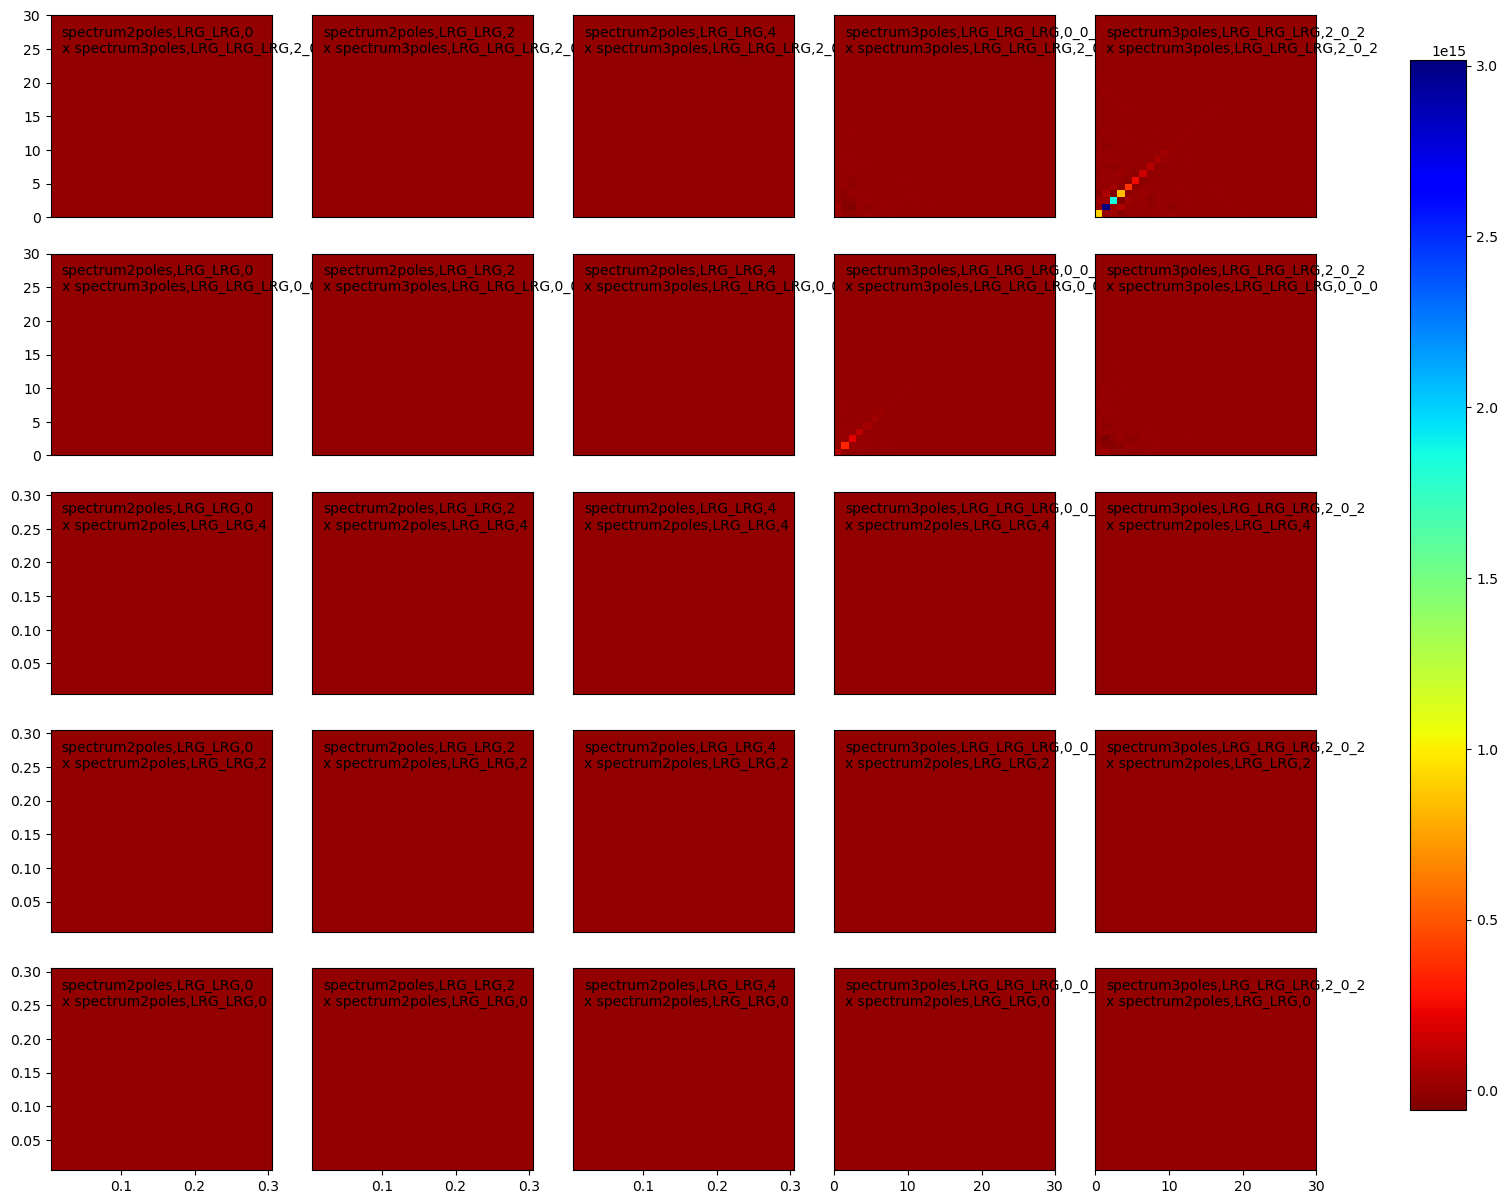

In [21]:

from lsstypes import ObservableTree

# For each mock realisation
combined_mocks = []
for imock in range(1000):
    p_poles = mocks[imock]                 # Mesh2SpectrumPoles
    b_poles = mocks_bispec[imock]          # Mesh3SpectrumPoles (raveled)

    # Pack them into a single tree with labels
    combined = ObservableTree(
        branches=[p_poles, b_poles],
        observables=['spectrum2poles', 'spectrum3poles'],
        tracers=[('LRG', 'LRG'), ('LRG', 'LRG', 'LRG')]   # adjust to your tracers
    )
    combined_mocks.append(combined)

# Compute covariance over the list of combined mocks
joint_cov = lsstypes.cov(combined_mocks)

joint_cov.plot()

combined_observable = ObservableTree(
        branches=[data_sel, data_bispec],
        observables=['spectrum2poles', 'spectrum3poles'],
        tracers=[('LRG', 'LRG'), ('LRG', 'LRG', 'LRG')]   # adjust to your tracers
    )

In [22]:
# NOTE: parameter customization must happen AFTER building the observables above, not before:
# Spectrum2PolesObservable.__init__ calls theory.update(k=..., ells=...) internally to align the
# theory's grid with the data, which (being a full re-__init__) would otherwise silently
# discard any customization made on theory's params beforehand.
#
# The P theory is Kaiser and the B theory is FOLPS: two different bias models, each declaring its
# own `b1` and `sn0` with its own prior. This is one tracer, so a joint fit must vary a single
# copy of each. `share_params` says so explicitly -- same-named Parameters that are distinct
# objects are unified only when they agree, and these do not, so the build refuses the tree
# rather than silently keeping one side's prior. Done here, after the observables above re-ran
# the theories' __init__.
from desilike.base import share_params

share_params([theory, theory_b])

params = get_params(observable_b)
params['b2'].update(value=b2)  # start from the truth
params['bs'].update(value=bs)
params['c1'].update(fixed=True, value=0.)
params['c2'].update(fixed=True, value=0.)
params['X_FoG'].update(fixed=True, value=0.)

likelihood = ObservablesGaussianLikelihood(observables=[observable, observable_b], covariance = joint_cov)

# the shared parameters, once, through the likelihood that joins them
params = get_params(likelihood)
params['b1'].update(value=b1)  # start from the truth
# Narrow reference distributions (used to draw starting points for profilers / samplers)
params['dm'].update(ref={'limits': [-0.001, 0.001]})
params['df'].update(ref={'limits': [0.99, 1.01]})
params['dA'].update(fixed=False, ref={'limits': [0.01, 2.]})
for name in ['qpar', 'qper']: params[name].update(ref={'limits': [0.998, 1.002]})

# NOTE: if we wanted to fit xi instead:
# theory = KaiserTracerCorrelation2Poles(template=template)
# observable = Correlation2PolesObservable(data=data_sel, covariance=covariance,
#                                          theory=theory)  # with data_sel = data.get(ells=[0, 2]).select(s=(40., 160.))
# The rest would be the same

setup_logging()
pipe = build(likelihood)
print('logL at default parameters =', pipe())

Calculating matrices (no save path specified)
logL at default parameters = -48.04354515748173


In [23]:
from desilike.emulators import Emulator, Space

# Same for the bispectrum theory. b2, bs, sn0 and snb0 enter the tree-level bispectrum
# linearly, so a single level is exact along those axes; `budget` then buys the interaction
# terms between the remaining ones.
space = Space(bounds={'qpar': (0.95, 1.05), 'qper': (0.95, 1.05), 'df': (0.9, 1.1),
                      'dA': (0.01, 2.), 'dm': (-0.1, 0.1), 'b1': (1.6, 2.4),
                      'b2': (-3., 4.), 'bs': (-3.5, 3.), 'sn0': (-0.5, 0.5), 'snb0': (-1.5, 1.5)},
              levels={'b2': 1, 'bs': 1, 'sn0': 1, 'snb0': 1})
emulator_b = Emulator(theory_b, space, budget=2)
print(len(emulator_b.nodes()), 'nodes')
emulator_b.train()

emulated_b = emulator_b.to_calculator()
point = dict(qpar=1.002, qper=0.998, dm=0.005, df=1.005, dA=1.005, b1=2.1, b2=0.6, bs=-0.3, sn0=0.1, snb0=0.1)
poles_true = np.asarray(build(theory_b)(**point))
build(emulated_b)(**point)
print('Max relative emulation error:', np.max(np.abs(np.asarray(emulated_b.poles) / poles_true - 1.)))

import os
base_dir = '_tests'
os.makedirs(base_dir, exist_ok=True)
bispec_emulator_fn = os.path.join(base_dir, 'bispec_Ap_kaiser_emulator.h5')
emulator_b.write(bispec_emulator_fn)

Calculating matrices (no save path specified)
213 nodes
[000019.40]  09-16 23:58  Emulator                     INFO     training on 213 nodes over 10 parameters; 0 handled exactly
[000019.40]  09-16 23:58  Emulator                     INFO     node box: qpar [0.95, 1.05], qper [0.95, 1.05], df [0.9, 1.1], dA [0.01, 2], dm [-0.1, 0.1], b1 [1.6, 2.4], b2 [-3, 4], bs [-3.5, 3], sn0 [-0.5, 0.5], snb0 [-1.5, 1.5]
[000019.40]  09-16 23:58  TrainingSet                  INFO     213/213 nodes to evaluate; no checkpoint (nothing is resumable)
[000020.27]  09-16 23:58  TrainingSet                  INFO     50/213 nodes
[000020.31]  09-16 23:58  TrainingSet                  INFO     100/213 nodes
[000020.35]  09-16 23:58  TrainingSet                  INFO     150/213 nodes
[000020.40]  09-16 23:58  TrainingSet                  INFO     200/213 nodes
[000020.41]  09-16 23:58  TrainingSet                  INFO     training complete (213/213 nodes)
Calculating matrices (no save path specified)
Max r

'_tests/bispec_Ap_kaiser_emulator.h5'

In [24]:
from desilike import Sampler, Posterior
from desilike.samplers import Zeus, PocoMC, Nautilus, Emcee


# Swap the theory for its emulator: update() re-runs the observable's __init__ in-place with
# the new theory (the likelihood holds the same observable instance, so it picks up the swap
# when we rebuild below).
#emulated_b = Emulator.read(bispec_emulator_fn).to_calculator()
#observable_b.update(theory=emulated_b)

# Sample the posterior = likelihood + priors: wrap the likelihood in Posterior.
pipe = build(Posterior(likelihood))
! rm -rfv _tests/chain_fs_shapefit_Ap_bispec/
sampler = Sampler(pipe, kernel=Emcee(), rng=42, output_dir='_tests/chain_fs_shapefit_Ap_bispec')
# We run samples until convergence, considered reached when Gelman-Rubin stabilizes below 1.05
samples = sampler.run(min_steps=2000, gelman_rubin=1.01)
#samples = sampler.run()

Calculating matrices (no save path specified)


/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/conda/lib/python3.12/pty.py:95: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
removed '_tests/chain_fs_shapefit_Ap_bispec/samples_1.h5'
removed '_tests/chain_fs_shapefit_Ap_bispec/checks.json'
removed '_tests/chain_fs_shapefit_Ap_bispec/rng_1.json'
removed directory '_tests/chain_fs_shapefit_Ap_bispec/'
[000035.49]  09-16 23:59  EnsembleSampler              INFO     Varied parameters: ['qpar', 'qper', 'df', 'dm', 'dA', 'b1', 'sn0', 'b2', 'bs', 'snb0']
[000035.50]  09-16 23:59  EnsembleSampler              INFO     Samples will be written to: _tests/chain_fs_shapefit_Ap_bispec
[000050.41]  09-16 23:59  Emcee                        INFO     total likelihood evaluations: 11960
[000050.51]  09-16 23:59  EnsembleSampler              INFO     Diagnostics:
[000050.57]  09-16 23:59  EnsembleSampler              INFO     Gelman-Rubin: 

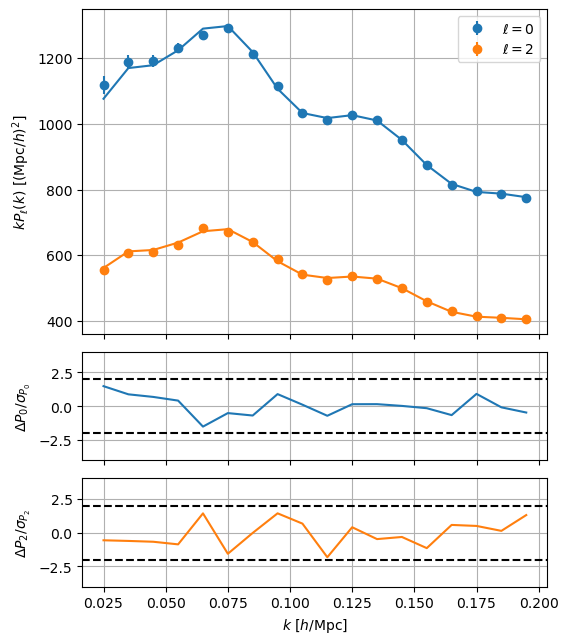

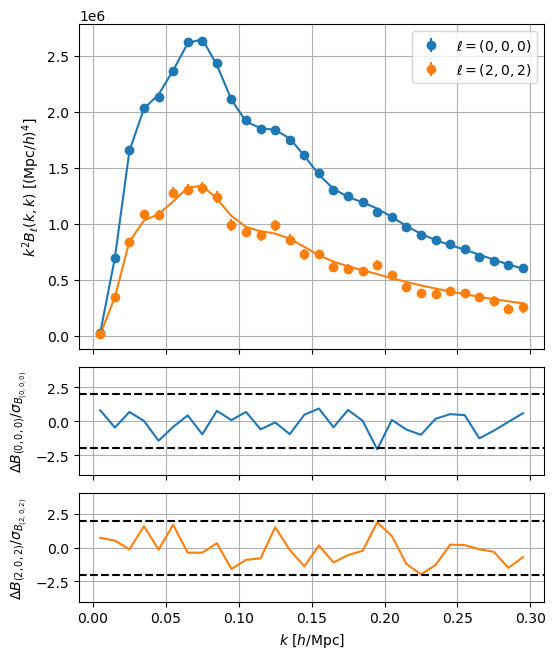

In [25]:
# Evaluate the likelihood at the maximum-posterior sample and plot the fit
names = get_params(likelihood).select(varied=True, derived=False).names()
idx = np.unravel_index(np.argmax(samples.logposterior), samples.logposterior.shape)
best = {name: np.asarray(samples[name].value)[idx] for name in names}
pipe(**best)
observable.plot()
plt.show()
observable_b.plot()
plt.show()

In [26]:
chain = samples.remove_burnin(0.5)[::10]
print(chain.to_stats(tablefmt='pretty'))

+------+---------+---------+---------+--------+-----------------+-----------------+
|      | argmax  |  mean   | median  |  std   | quantile:1sigma | interval:1sigma |
+------+---------+---------+---------+--------+-----------------+-----------------+
| qpar | 0.9997  | 1.0004  | 1.0003  | 0.0022 | +0.0022/-0.0022 | +0.0021/-0.0023 |
| qper | 0.9944  | 0.9949  | 0.9948  | 0.0038 | +0.0039/-0.0038 | +0.0038/-0.0039 |
|  df  | 1.0019  | 1.0008  | 1.0008  | 0.0084 | +0.0085/-0.0084 | +0.0078/-0.0089 |
|  dm  | -0.0039 | -0.0045 | -0.0044 | 0.0042 | +0.0042/-0.0043 | +0.0043/-0.0042 |
|  dA  |  0.985  |  0.989  |  0.989  | 0.023  |  +0.024/-0.024  |  +0.021/-0.026  |
|  b1  |  2.006  |  2.002  |  2.002  | 0.021  |  +0.021/-0.021  |  +0.021/-0.021  |
| sn0  | 0.0033  | 0.0036  | 0.0036  | 0.0027 | +0.0026/-0.0026 | +0.0026/-0.0027 |
|  b2  |  0.487  |  0.496  |  0.494  | 0.055  |  +0.055/-0.055  |  +0.049/-0.061  |
|  bs  |  -0.37  |  -0.37  |  -0.37  |  0.15  |   +0.15/-0.15   |   +0.16/-0

Removed no burn in
Removed no burn in
[000308.94]  09-17 00:03  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral
[000308.94]  09-17 00:03  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral


[000311.27]  09-17 00:03  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral
[000311.27]  09-17 00:03  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral


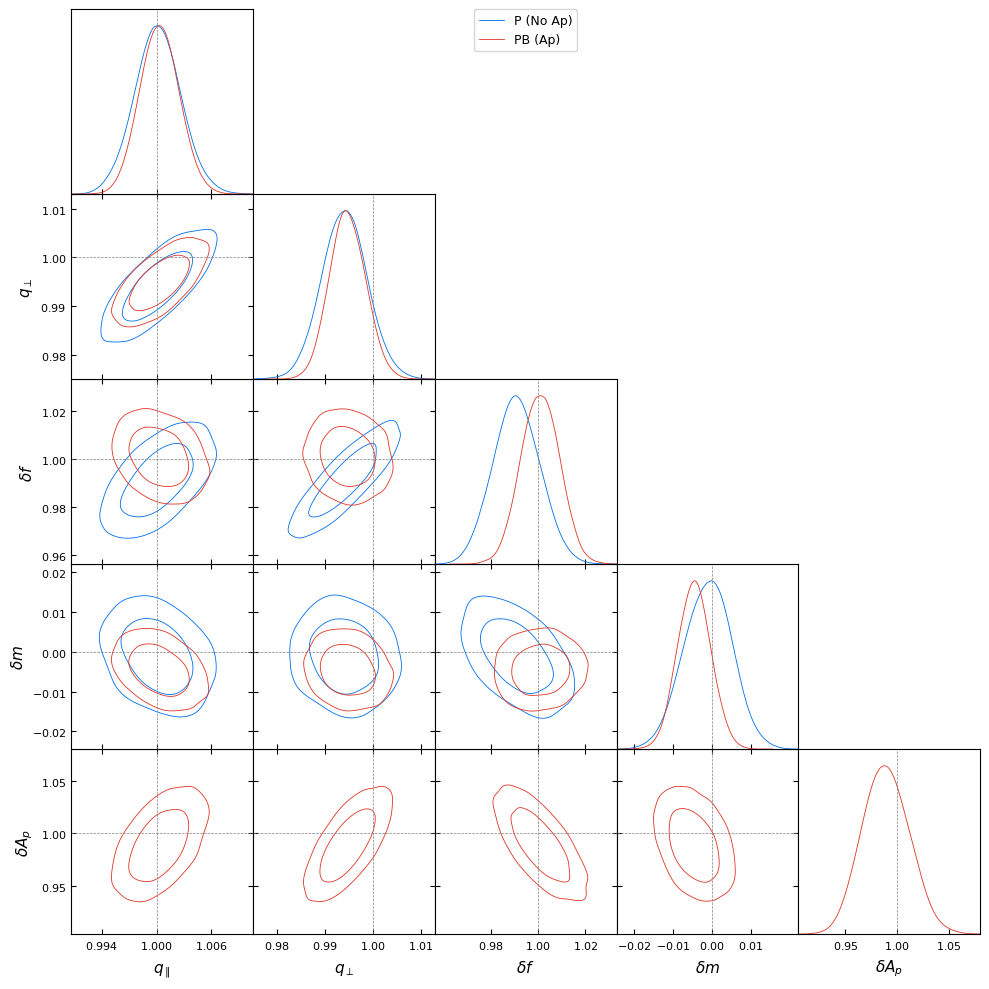

In [30]:
from desilike.samples import plotting
from desilike.samples import MCSamples
chain = MCSamples.read('_tests/chain_fs_shapefit_Ap/samples_1.h5').remove_burnin(0.3)[::5]
chain_bispec = MCSamples.read('_tests/chain_fs_shapefit_Ap_bispec/samples_1.h5').remove_burnin(0.3)[::5]
chain_no_Ap = MCSamples.read('_tests/chain_fs_shapefit/samples_1.h5').remove_burnin(0.3)[::5]
#chain_no_Ap['dA'] = np.random.uniform(size = chain_no_Ap['dm'].value.shape) + 0.5

plotting.plot_triangle([chain_no_Ap, chain_bispec], 
                       markers={'qpar': 1., 'qper': 1., 'df': 1., 'dA':1., 'dm': 0., 'b1': b, 'sn0': 0},
                       params = ['qpar', 'qper', 'df', 'dm', 'dA', 'logdA'],
                      labels = ["P (No Ap)", "PB (Ap)"])

Removed no burn in
Removed no burn in
[000343.58]  09-17 00:04  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral
[000343.58]  09-17 00:04  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral


[000347.37]  09-17 00:04  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral
[000347.38]  09-17 00:04  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral


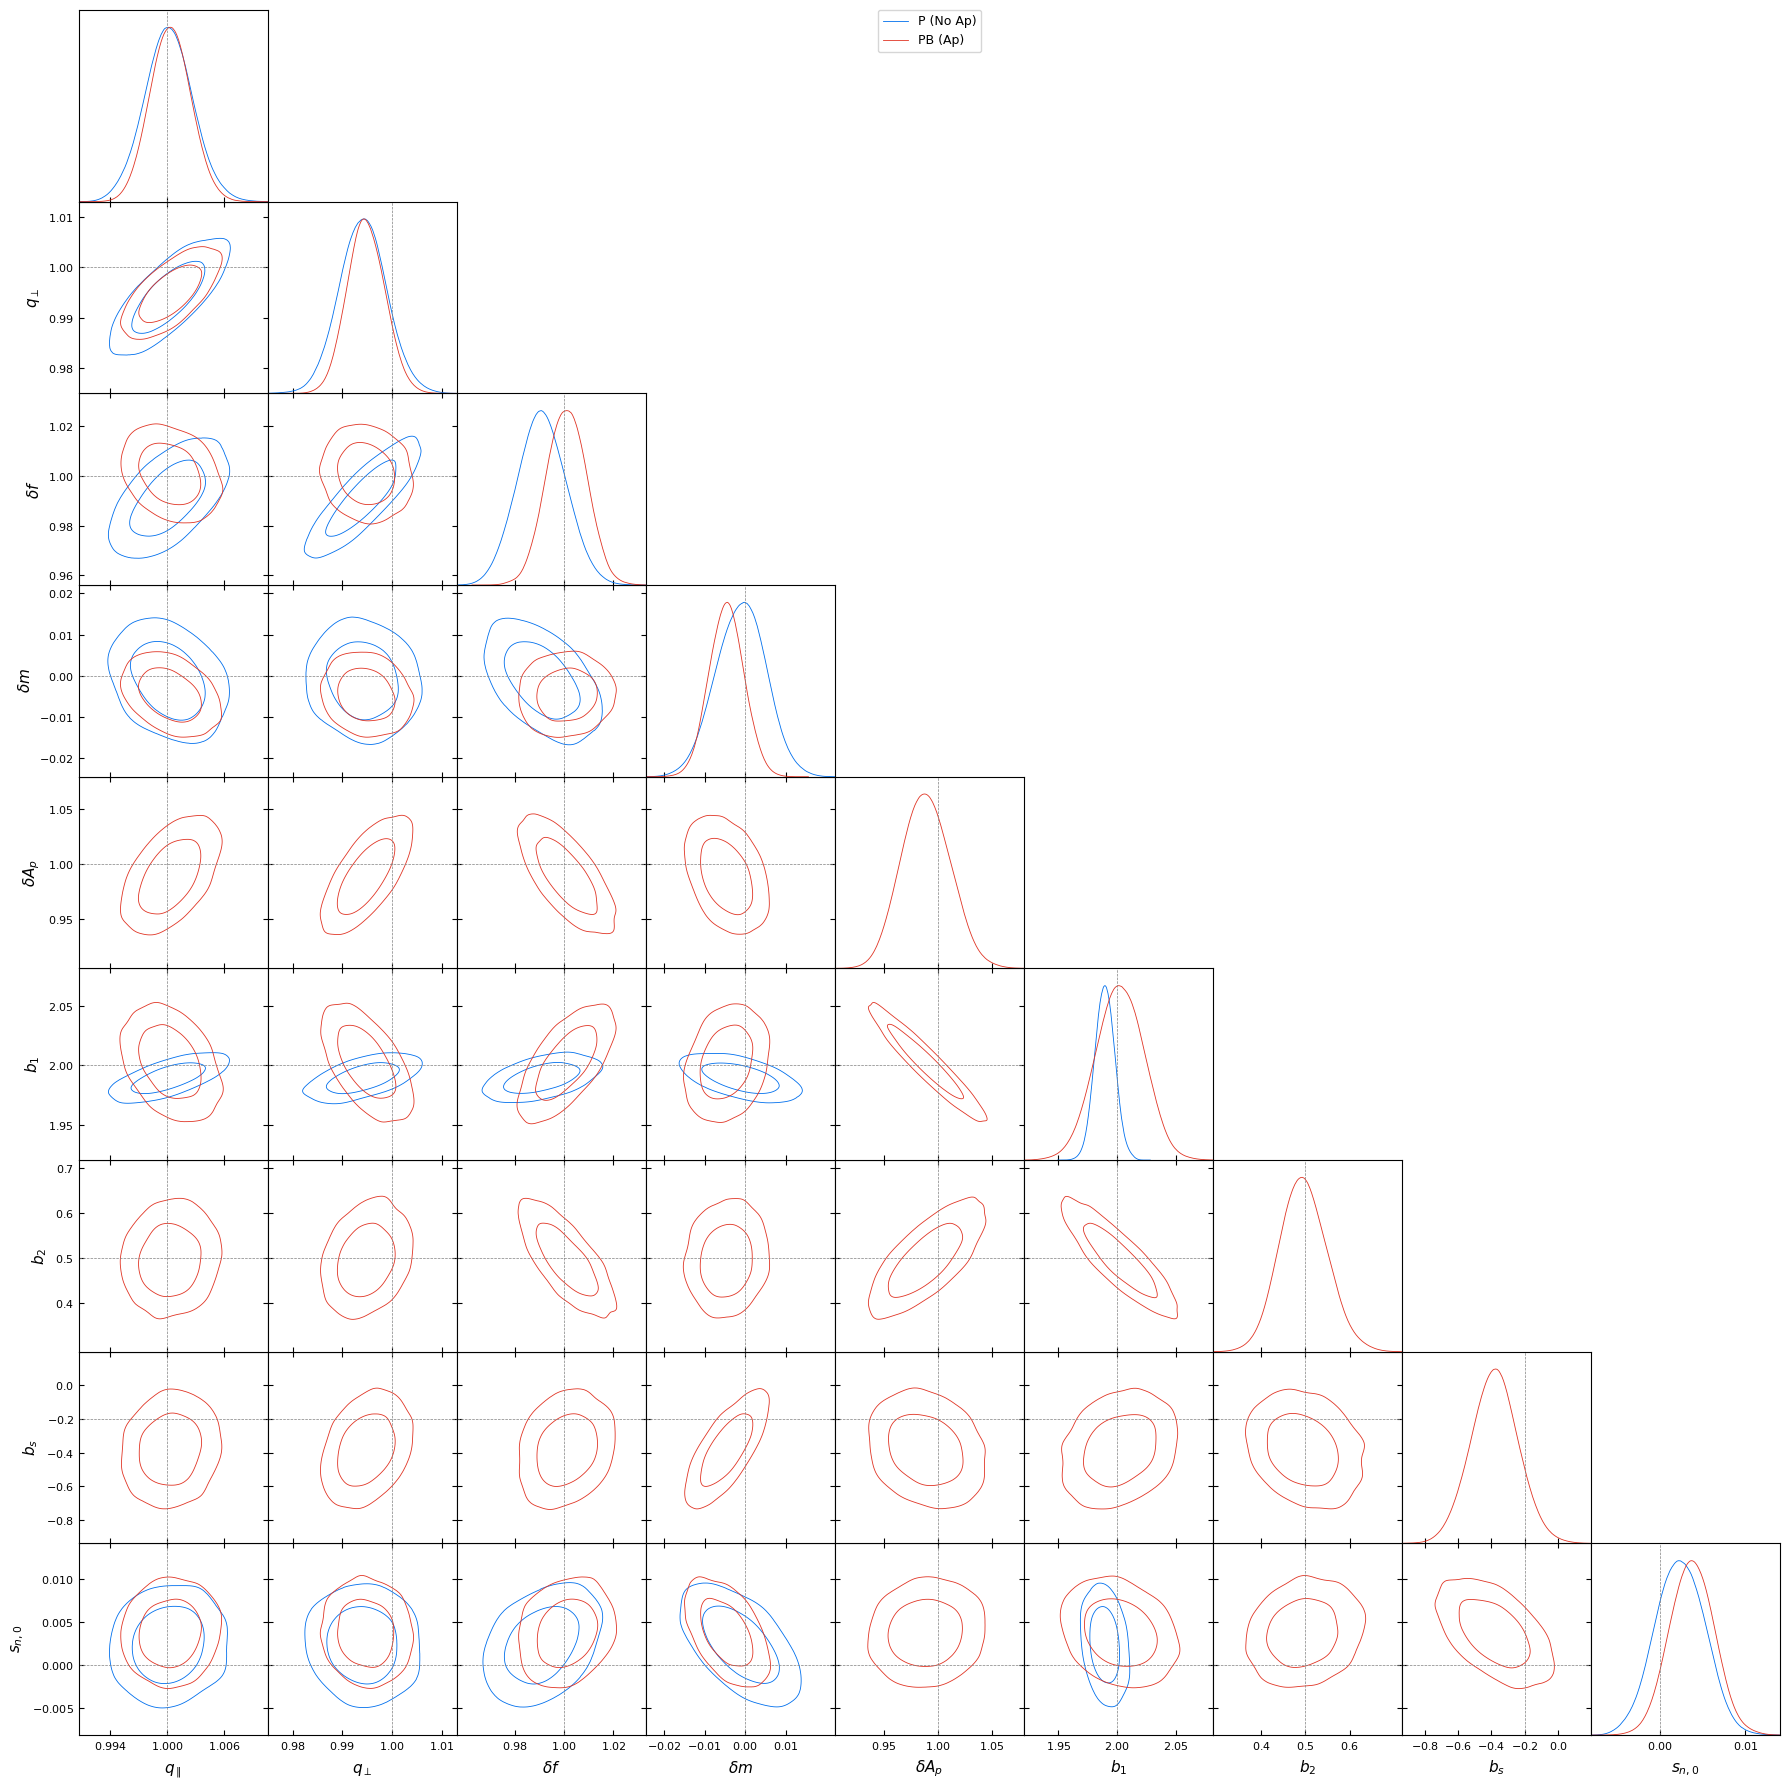

In [31]:
plotting.plot_triangle([chain_no_Ap, chain_bispec], 
                       params = ['qpar', 'qper', 'df', 'dm', 'dA', 'b1', 'b2', 'bs', 'sn0', 'sn0b'],
                       markers={'qpar': 1., 'qper': 1., 'df': 1., 'dA':1., 'dm': 0., 'b1': b1, 'sn0': 0., 'b2':b2, 'bs':bs, 'sn0b':0},
                      labels = ["P (No Ap)", "PB (Ap)"])

# ShapeFit with free dn

So far `dn` (the second-order, scale-independent ShapeFit parameter, exactly degenerate with
n_s - n_s^ref) was fixed to 0, as in the DESI modified-gravity configuration: any n_s offset is
then stored inside `dm`.  Here we repeat the compression with `dn` free, so that the tilt is
measured by the data instead of being absorbed by the slope.  The chain is saved to
`_tests/chain_fs_shapefit_dn` for `compression_examples.ipynb` to reinterpret.

In [ ]:
template = ShapeFitSpectrum2Template(z=z, fiducial='DESI')
theory = KaiserTracerSpectrum2Poles(template=template)

data_sel = data.get(ells=[0, 2]).select(k=(0.02, 0.2))
covariance = lsstypes.cov(mocks).at.observable.match(data_sel)
observable = Spectrum2PolesObservable(data=data_sel, covariance=covariance, theory=theory)

params = get_params(observable)
params['b1'].update(value=b)  # start from the truth
params['dn'].update(fixed=False)  # the only difference with the previous sections
params['dn'].update(ref={'limits': [-0.001, 0.001]})
params['dm'].update(ref={'limits': [-0.001, 0.001]})
params['df'].update(ref={'limits': [0.99, 1.01]})
for name in ['qpar', 'qper']: params[name].update(ref={'limits': [0.998, 1.002]})

likelihood = ObservablesGaussianLikelihood(observables=[observable])
pipe = build(Posterior(likelihood))
print('varied:', [param.name for param in get_params(likelihood) if param.varied])

In [ ]:
sampler_dn = Sampler(pipe, kernel=Zeus(), rng=43, output_dir='_tests/chain_fs_shapefit_dn')
samples_dn = sampler.run(min_steps=500, gelman_rubin=1.05)

In [ ]:
chain_dn = samples_dn.remove_burnin(0.3)
print(chain_dn.to_stats(tablefmt='pretty'))

In [ ]:
from desilike.samples import plotting
# dm and dn are strongly anti-correlated: together they carry the slope and the tilt of the
# broadband, i.e. the omega_m and n_s information that a dn = 0 analysis folds into dm alone
plotting.plot_triangle([chain, chain_dn], filled=False, labels=['dn fixed', 'dn free'],
                       params=['qpar', 'qper', 'df', 'dm', 'dn'],
                       markers={'qpar': 1., 'qper': 1., 'df': 1., 'dm': 0., 'dn': 0.})
plt.show()